# ft2 vs CLS — one-day identity check (20150101)

Compare the `cawohdcst_ft2` warm-start of **2015-01-01** with the CLS archive for the same day.

| Item | Value |
|------|--------|
| Slurm job | `610471` (`HDCST-FT`, partition HDCAST) |
| Mode | Continuing warm start. `NRREC = -1`. **No** `--day1` |
| Prior day | `20141231` triad copied from CLS into ft2 (`roms_rst`, `wrfrst`, SWAN hotstart) |
| Atmosphere IC | `wrfinput_d01` / `wrfbdy_d01` copied from the CLS run directory. Metgrid on HDCAST failed (MPI/OFI), so WPS was not regenerated |
| ft2 raw output | `/scratch/cawohdcst_ft2/inacawo-iht/cawo_output/f20150101` |
| CLS raw output | `/scratch/cawohdcst/data/cawo_hindcast_outputs/f20150101` |

Kernel: `hindcast`. File-size equality is not scientific identity: ROMS history files differ in byte size even when early fields match. This notebook compares numeric fields.

Read-only. It does not submit jobs or write model output.


In [2]:
from pathlib import Path

import numpy as np
from netCDF4 import Dataset

CLS = Path("/scratch/cawohdcst/data/cawo_hindcast_outputs/f20150101")
FT2 = Path("/scratch/cawohdcst_ft2/inacawo-iht/cawo_output/f20150101")
assert CLS.is_dir(), CLS
assert FT2.is_dir(), FT2
print("CLS", CLS)
print("FT2", FT2)


CLS /scratch/cawohdcst/data/cawo_hindcast_outputs/f20150101
FT2 /scratch/cawohdcst_ft2/inacawo-iht/cawo_output/f20150101


## File inventory

CLS stores the ROMS restart under `postprocessed/roms_rst`, not next to the history files. An extra `cawo_g2.8.0_rst_*.nc` on the ft2 side is expected.


In [3]:
cls_names = {p.name for p in CLS.iterdir() if p.is_file()}
ft2_names = {p.name for p in FT2.iterdir() if p.is_file()}
common = sorted(cls_names & ft2_names)
only_cls = sorted(cls_names - ft2_names)
only_ft2 = sorted(ft2_names - cls_names)

same_size, diff_size = [], []
for name in common:
    sa = (CLS / name).stat().st_size
    sb = (FT2 / name).stat().st_size
    (same_size if sa == sb else diff_size).append((name, sa, sb))

print(f"common={len(common)}  same_size={len(same_size)}  diff_size={len(diff_size)}")
print("only CLS:", only_cls or "none")
print("only ft2:", only_ft2 or "none")
print("size mismatches (first 8):")
for name, sa, sb in diff_size[:8]:
    print(f"  {name}  cls={sa}  ft2={sb}  delta={sb - sa}")


common=74  same_size=50  diff_size=24
only CLS: none
only ft2: ['cawo_g2.8.0_rst_20150101_12.nc']
size mismatches (first 8):
  cawo_g2.8.0_his_20150101_12_00002.nc  cls=3549399564  ft2=3540203840  delta=-9195724
  cawo_g2.8.0_his_20150101_12_00003.nc  cls=3549399564  ft2=3540203840  delta=-9195724
  cawo_g2.8.0_his_20150101_12_00004.nc  cls=3549399564  ft2=3540203840  delta=-9195724
  cawo_g2.8.0_his_20150101_12_00005.nc  cls=3549399564  ft2=3540203840  delta=-9195724
  cawo_g2.8.0_his_20150101_12_00006.nc  cls=3549399564  ft2=3540203840  delta=-9195724
  cawo_g2.8.0_his_20150101_12_00007.nc  cls=3549399564  ft2=3540203840  delta=-9195724
  cawo_g2.8.0_his_20150101_12_00008.nc  cls=3549399564  ft2=3540203840  delta=-9195724
  cawo_g2.8.0_his_20150101_12_00009.nc  cls=3549399564  ft2=3540203840  delta=-9195724


## Field difference

`maxabs` is the maximum absolute difference on the requested slice. NaN in both files counts as zero. Ocean checks use the surface level of `temp` and `salt` so a 3.5 GiB history file is not loaded in full.


In [4]:
def maxabs(left, right):
    a = np.ma.filled(np.asarray(left), np.nan).astype("float64")
    b = np.ma.filled(np.asarray(right), np.nan).astype("float64")
    if a.shape != b.shape:
        raise ValueError(f"shape {a.shape} vs {b.shape}")
    diff = np.abs(a - b)
    both_nan = np.isnan(a) & np.isnan(b)
    diff = np.where(both_nan, 0.0, diff)
    finite = np.isfinite(diff)
    if not finite.any():
        return {"maxabs": None, "n": 0}
    return {"maxabs": float(diff[finite].max()), "n": int(finite.sum()), "diff": diff, "wet": np.isfinite(a) & np.isfinite(b)}


def compare_file(name, slices):
    print(f"== {name} ==")
    with Dataset(CLS / name) as src, Dataset(FT2 / name) as dst:
        rows = []
        for var, index in slices.items():
            if var not in src.variables or var not in dst.variables:
                print(f"  {var}: absent")
                continue
            stats = maxabs(src.variables[var][index], dst.variables[var][index])
            print(f"  {var}: maxabs={stats['maxabs']:.6e}  n={stats['n']}")
            rows.append((var, stats))
    return rows


In [5]:
ocean_surface = {
    "zeta": (slice(None),),
    "temp": (slice(None), -1),
    "salt": (slice(None), -1),
}
early = compare_file("cawo_g2.8.0_his_20150101_12_00002.nc", ocean_surface)
late = compare_file("cawo_g2.8.0_his_20150101_12_00025.nc", ocean_surface)


== cawo_g2.8.0_his_20150101_12_00002.nc ==


  zeta: maxabs=0.000000e+00  n=2298864
  temp: maxabs=0.000000e+00  n=2298864
  salt: maxabs=0.000000e+00  n=2298864
== cawo_g2.8.0_his_20150101_12_00025.nc ==
  zeta: maxabs=9.485692e-02  n=2298864
  temp: maxabs=2.101772e+00  n=2298864
  salt: maxabs=7.127007e+00  n=2298864


In [6]:
wrf_fields = {
    "TA2": (slice(None),),
    "UX10": (slice(None),),
    "VX10": (slice(None),),
    "SLPRS": (slice(None),),
    "RAIN": (slice(None),),
}
wrf_early = compare_file("wrfhtr_d01_2015-01-01_13:00:00", wrf_fields)
wrf_late = compare_file("wrfhtr_d01_2015-01-02_12:00:00", wrf_fields)


== wrfhtr_d01_2015-01-01_13:00:00 ==
  TA2: maxabs=0.000000e+00  n=2305200
  UX10: maxabs=0.000000e+00  n=2305200
  VX10: maxabs=0.000000e+00  n=2305200
  SLPRS: maxabs=0.000000e+00  n=2305200


  RAIN: maxabs=4.164711e+02  n=2305200
== wrfhtr_d01_2015-01-02_12:00:00 ==
  TA2: maxabs=6.001831e+00  n=2305200
  UX10: maxabs=2.796495e+01  n=2305200
  VX10: maxabs=2.041393e+01  n=2305200
  SLPRS: maxabs=2.394592e+00  n=2305200
  RAIN: maxabs=4.164705e+02  n=2305200


## Where the ocean diverges

Counts are wet points on the surface of the last history file (`his_00025`). A handful of large salt differences is a different conclusion from a widespread drift.


In [7]:
salt_stats = dict(late)["salt"]
wet = salt_stats["wet"]
delta = salt_stats["diff"]
print("wet points", int(wet.sum()))
for threshold in (1e-6, 1e-3, 0.1, 1.0):
    print(f"  |dsalt| > {threshold:g}: {int((delta[wet] > threshold).sum())}")


wet points 2298864
  |dsalt| > 1e-06: 1857519
  |dsalt| > 0.001: 370988
  |dsalt| > 0.1: 27489
  |dsalt| > 1: 719


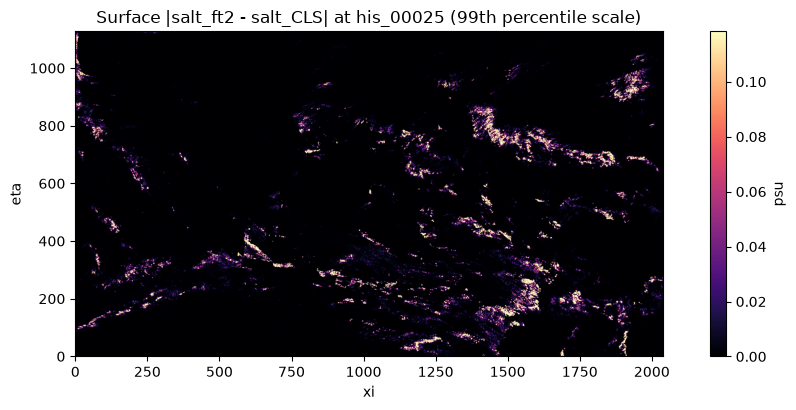

In [8]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("matplotlib is not installed; table above is the record")

if plt is not None:
    show = np.squeeze(np.where(wet, delta, np.nan))
    finite = show[np.isfinite(show)]
    vmax = float(np.quantile(finite, 0.99)) if finite.size else 1.0
    fig, ax = plt.subplots(figsize=(10, 4.2))
    image = ax.imshow(show, origin="lower", cmap="magma", vmin=0, vmax=max(vmax, 1e-6))
    ax.set_title("Surface |salt_ft2 - salt_CLS| at his_00025 (99th percentile scale)")
    ax.set_xlabel("xi")
    ax.set_ylabel("eta")
    fig.colorbar(image, ax=ax, label="psu")
    fig.tight_layout()
    plt.show()


## Ocean state

History files in this archive store `zeta`, `temp`, and `salt` only. The full prognostic state (`zeta`, `ubar`, `vbar`, `u`, `v`, `temp`, `salt`) is the ROMS restart written at the end of the day.

| Side | Restart |
|------|---------|
| ft2 | `/scratch/cawohdcst_ft2/inacawo-iht/cawo_output/f20150101/cawo_g2.8.0_rst_20150101_12.nc` |
| CLS | `/scratch/cawohdcst/data/postprocessed/roms_rst/f20150101/cawo_g2.8.0_rst_20150101_12.nc` |

`maxabs` below is over every horizontal point and every index of the perfect-restart time slots (`two` / `three`), one slab at a time.

In [9]:
from itertools import product

CLS_RST = Path("/scratch/cawohdcst/data/postprocessed/roms_rst/f20150101/cawo_g2.8.0_rst_20150101_12.nc")
FT2_RST = FT2 / "cawo_g2.8.0_rst_20150101_12.nc"
STATE_VARS = ("zeta", "ubar", "vbar", "u", "v", "temp", "salt")


def full_maxabs(left, right):
    """Maximum absolute difference over all leading indexes, one horizontal slab at a time."""
    if left.shape != right.shape:
        return {"maxabs": None, "n": 0, "note": f"shape {left.shape} vs {right.shape}"}
    if left.ndim <= 2:
        stats = maxabs(left[:], right[:])
        return {"maxabs": stats["maxabs"], "n": stats["n"], "note": "full"}
    peak = 0.0
    count = 0
    any_finite = False
    for idx in product(*(range(size) for size in left.shape[:-2])):
        stats = maxabs(left[idx], right[idx])
        count += stats["n"]
        if stats["maxabs"] is None:
            continue
        any_finite = True
        peak = max(peak, stats["maxabs"])
    return {
        "maxabs": peak if any_finite else None,
        "n": count,
        "note": f"slabs={int(np.prod(left.shape[:-2]))}",
    }


def report_state(label, path_a, path_b):
    print(f"== {label} ==")
    print(path_a)
    print(path_b)
    with Dataset(path_a) as src, Dataset(path_b) as dst:
        for name in ("ocean_time",) + STATE_VARS:
            if name not in src.variables or name not in dst.variables:
                print(f"  {name}: absent")
                continue
            stats = full_maxabs(src.variables[name], dst.variables[name])
            value = stats["maxabs"]
            shown = "None" if value is None else f"{value:.6e}"
            print(f"  {name}: maxabs={shown}  n={stats['n']}  {stats['note']}")


report_state("restart ocean state 20150101 12Z", CLS_RST, FT2_RST)

== restart ocean state 20150101 12Z ==
/scratch/cawohdcst/data/postprocessed/roms_rst/f20150101/cawo_g2.8.0_rst_20150101_12.nc
/scratch/cawohdcst_ft2/inacawo-iht/cawo_output/f20150101/cawo_g2.8.0_rst_20150101_12.nc
  ocean_time: maxabs=0.000000e+00  n=1  full


  zeta: maxabs=9.485692e-02  n=6896592  slabs=3
  ubar: maxabs=6.596066e-02  n=6893208  slabs=3
  vbar: maxabs=7.167330e-02  n=6890478  slabs=3
  u: maxabs=3.729850e-01  n=321683040  slabs=140
  v: maxabs=3.964397e-01  n=321555640  slabs=140
  temp: maxabs=2.101772e+00  n=321840960  slabs=140
  salt: maxabs=7.127007e+00  n=321840960  slabs=140


In [10]:
def column_maxabs(name, filename):
    """Per-s_rho maxabs for a history tracer. Level 0 is the bottom; -1 is the surface."""
    print(f"== {filename} {name} by s_rho ==")
    with Dataset(CLS / filename) as src, Dataset(FT2 / filename) as dst:
        left = src.variables[name]
        right = dst.variables[name]
        nlev = left.shape[1]
        peaks = []
        for level in range(nlev):
            stats = maxabs(left[0, level], right[0, level])
            peaks.append(stats["maxabs"] or 0.0)
        peaks = np.asarray(peaks)
        print(f"  levels={nlev}  column_max={peaks.max():.6e}  surface={peaks[-1]:.6e}  bottom={peaks[0]:.6e}")
        hot = np.argsort(peaks)[-3:][::-1]
        for level in hot:
            print(f"  largest level {int(level)}: {peaks[level]:.6e}")
    return peaks


for his_name in (
    "cawo_g2.8.0_his_20150101_12_00002.nc",
    "cawo_g2.8.0_his_20150101_12_00025.nc",
):
    for tracer in ("temp", "salt"):
        column_maxabs(tracer, his_name)

== cawo_g2.8.0_his_20150101_12_00002.nc temp by s_rho ==
  levels=70  column_max=0.000000e+00  surface=0.000000e+00  bottom=0.000000e+00
  largest level 69: 0.000000e+00
  largest level 68: 0.000000e+00
  largest level 67: 0.000000e+00
== cawo_g2.8.0_his_20150101_12_00002.nc salt by s_rho ==
  levels=70  column_max=0.000000e+00  surface=0.000000e+00  bottom=0.000000e+00
  largest level 69: 0.000000e+00
  largest level 68: 0.000000e+00
  largest level 67: 0.000000e+00
== cawo_g2.8.0_his_20150101_12_00025.nc temp by s_rho ==
  levels=70  column_max=2.101772e+00  surface=2.101772e+00  bottom=2.299156e-01
  largest level 69: 2.101772e+00
  largest level 31: 1.573574e+00
  largest level 59: 1.350212e+00
== cawo_g2.8.0_his_20150101_12_00025.nc salt by s_rho ==
  levels=70  column_max=7.127007e+00  surface=7.127007e+00  bottom=4.089298e-01
  largest level 69: 7.127007e+00
  largest level 68: 4.447466e+00
  largest level 67: 3.625013e+00


## Reading the result

Identical means `maxabs = 0` on the compared slice.

- The first ocean history record matching on `zeta` and surface `temp` means the copied ROMS restart was read.
- A non-zero `maxabs` on `his_00025` means the day is **not** identical to CLS by the end of the run, even when the file names line up.
- The restart section is the ocean state. `u`, `v`, `ubar`, and `vbar` are not in the history files. A non-zero restart `maxabs` means the state written at 12Z on 20150101 is not the CLS state.
- The history column check shows whether `temp` and `salt` differ only at the surface or through the water column. Level 0 is the bottom.
- WRF `wrfhtr` names in this archive are `TA2`, `UX10`, `VX10`, `SLPRS`, and `RAIN`, not the raw WRF names `T2` / `U10` / `PSFC`.


## Sampled fields, 1–7 January 2015

Surface comparison of ft2 against CLS for the warm-start chain **20150101–20150107**. Days after 1 January start from the ft2 restart of the previous day, not from a fresh CLS restart.

| Label | Variable | Slab |
|-------|----------|------|
| SWH | `Hwave` | significant wave height |
| arus | `u_eastward`, `v_northward` | surface `s_rho`; speed is `hypot(u, v)` |
| salinity | `salt` | surface `s_rho` |
| sea temperature | `temp` | surface `s_rho` |

Land fill `1e37` is excluded. Bias is `mean(ft2) − mean(CLS)`. Each hindcast day runs 12:00 UTC to 12:00 UTC the next day; the table uses the first history record (13:00) and the last (next-day 12:00).


In [1]:
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from netCDF4 import Dataset

CLS_ROOT = Path("/scratch/cawohdcst/data/cawo_hindcast_outputs")
FT2_ROOT = Path("/scratch/cawohdcst_ft2/inacawo-iht/cawo_output")
DATES = [datetime(2015, 1, 1) + timedelta(days=offset) for offset in range(7)]
BASE_FIELDS = (
    ("swh", "Hwave", None),
    ("arus_u", "u_eastward", -1),
    ("arus_v", "v_northward", -1),
    ("salinity", "salt", -1),
    ("seatemp", "temp", -1),
)
PLOT_FIELDS = ("swh", "arus", "salinity", "seatemp")
LABELS = {
    "swh": "SWH (m)",
    "arus": "arus (m/s)",
    "arus_u": "arus u (m/s)",
    "arus_v": "arus v (m/s)",
    "salinity": "salinity",
    "seatemp": "sea temp (C)",
}


def field_stats(left, right):
    a = np.asarray(left, dtype="float64").ravel()
    b = np.asarray(right, dtype="float64").ravel()
    valid = np.isfinite(a) & np.isfinite(b)
    a, b = a[valid], b[valid]
    count = int(a.size)
    if count == 0:
        empty = {key: np.nan for key in ("n", "cls_mean", "ft2_mean", "bias", "rmse", "maxabs", "corr", "nrmse")}
        empty["n"] = 0
        return empty
    delta = b - a
    cls_std = float(a.std())
    rmse = float(np.sqrt(np.mean(delta * delta)))
    corr = np.nan if cls_std == 0 or b.std() == 0 else float(np.corrcoef(a, b)[0, 1])
    return {
        "n": count,
        "cls_mean": float(a.mean()),
        "ft2_mean": float(b.mean()),
        "bias": float(delta.mean()),
        "rmse": rmse,
        "maxabs": float(np.max(np.abs(delta))),
        "corr": corr,
        "nrmse": rmse / cls_std if cls_std else np.nan,
    }


def read_surface(dataset, name, level):
    variable = dataset.variables[name]
    raw = variable[0] if level is None else variable[0, level]
    data = np.squeeze(np.ma.filled(np.ma.asarray(raw), np.nan)).astype("float64")
    data[np.abs(data) > 1e30] = np.nan
    return data


def load_hour(path):
    fields = {}
    with Dataset(path) as dataset:
        seconds = float(np.asarray(dataset.variables["ocean_time"][0]))
        stamp = datetime(1858, 11, 17) + timedelta(seconds=seconds)
        for key, name, level in BASE_FIELDS:
            fields[key] = read_surface(dataset, name, level)
    speed = np.hypot(fields["arus_u"], fields["arus_v"])
    speed[~np.isfinite(fields["arus_u"]) | ~np.isfinite(fields["arus_v"])] = np.nan
    fields["arus"] = speed
    return stamp, fields


rows = []
end_maps = {}
for day in DATES:
    tag = day.strftime("%Y%m%d")
    cls_dir = CLS_ROOT / f"f{tag}"
    ft2_dir = FT2_ROOT / f"f{tag}"
    pattern = f"cawo_g2.8.0_his_{tag}_12_*.nc"
    cls_files = {item.name: item for item in cls_dir.glob(pattern)}
    ft2_files = {item.name: item for item in ft2_dir.glob(pattern)}
    names = sorted(cls_files.keys() & ft2_files.keys())
    if not names:
        raise FileNotFoundError(f"no paired history for {tag}")
    print(f"{tag} hours={len(names)}", flush=True)
    last_cls = last_ft2 = None
    last_time = None
    for step, name in enumerate(names, start=1):
        cls_time, cls_fields = load_hour(cls_files[name])
        ft2_time, ft2_fields = load_hour(ft2_files[name])
        if cls_time != ft2_time:
            raise RuntimeError(f"time mismatch {tag} {name}: {cls_time} vs {ft2_time}")
        for key in ("swh", "arus_u", "arus_v", "arus", "salinity", "seatemp"):
            stats = field_stats(cls_fields[key], ft2_fields[key])
            stats.update(day=tag, time=cls_time, field=key)
            rows.append(stats)
        last_cls, last_ft2, last_time = cls_fields, ft2_fields, cls_time
    end_maps[tag] = (last_time, last_cls, last_ft2)

series = pd.DataFrame(rows)
edges = series.sort_values("time").groupby(["day", "field"], as_index=False).nth([0, -1])
metrics_table = edges[["day", "time", "field", "n", "bias", "rmse", "maxabs", "corr", "cls_mean", "ft2_mean"]]
metrics_table


20150101 hours=24


20150102 hours=24


20150103 hours=24


20150104 hours=24


20150105 hours=24


20150106 hours=24


20150107 hours=24


,day,time,field,n,bias,rmse,maxabs,corr,cls_mean,ft2_mean
0,20150101,2015-01-01 13:00:00,swh,1874969,0.000000,0.000000,0.000000,1.000000,1.655373,1.655373
1,20150101,2015-01-01 13:00:00,arus_u,1874969,0.000000,0.000000,0.000000,1.000000,0.027169,0.027169
2,20150101,2015-01-01 13:00:00,arus_v,1874969,0.000000,0.000000,0.000000,1.000000,-0.008925,-0.008925
3,20150101,2015-01-01 13:00:00,arus,1874969,0.000000,0.000000,0.000000,1.000000,0.295538,0.295538
4,20150101,2015-01-01 13:00:00,salinity,1874969,0.000000,0.000000,0.000000,1.000000,33.790774,33.790774
...,...,...,...,...,...,...,...,...,...,...
1002,20150107,2015-01-08 12:00:00,swh,1874969,-0.010257,0.111569,1.465077,0.988410,1.740088,1.729831
1003,20150107,2015-01-08 12:00:00,arus_u,1874969,0.000164,0.033609,0.673645,0.994926,0.053018,0.053182
1004,20150107,2015-01-08 12:00:00,arus_v,1874969,0.002369,0.031275,0.618173,0.991501,0.000476,0.002845
1005,20150107,2015-01-08 12:00:00,arus,1874969,-0.000090,0.032968,0.602193,0.989781,0.343857,0.343767


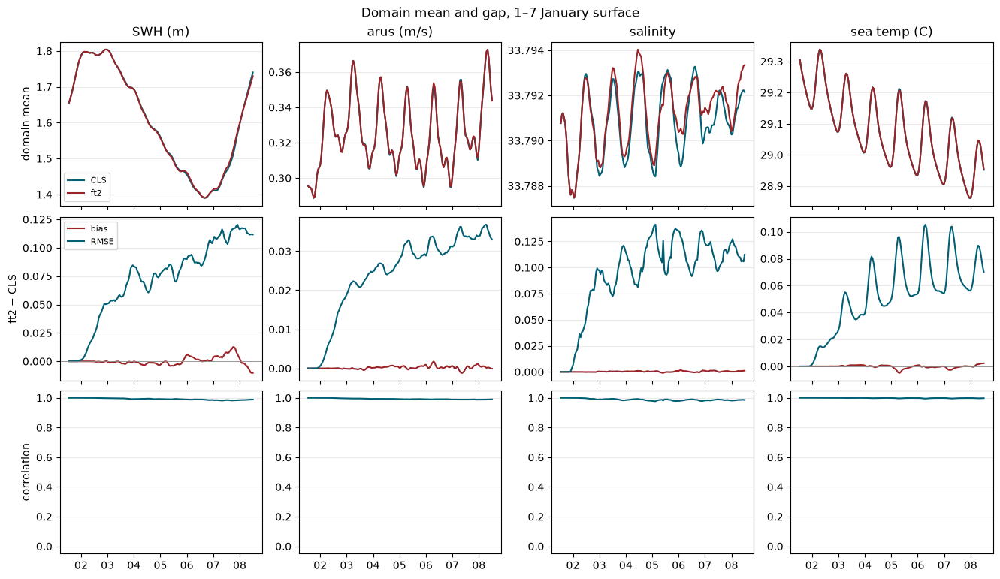

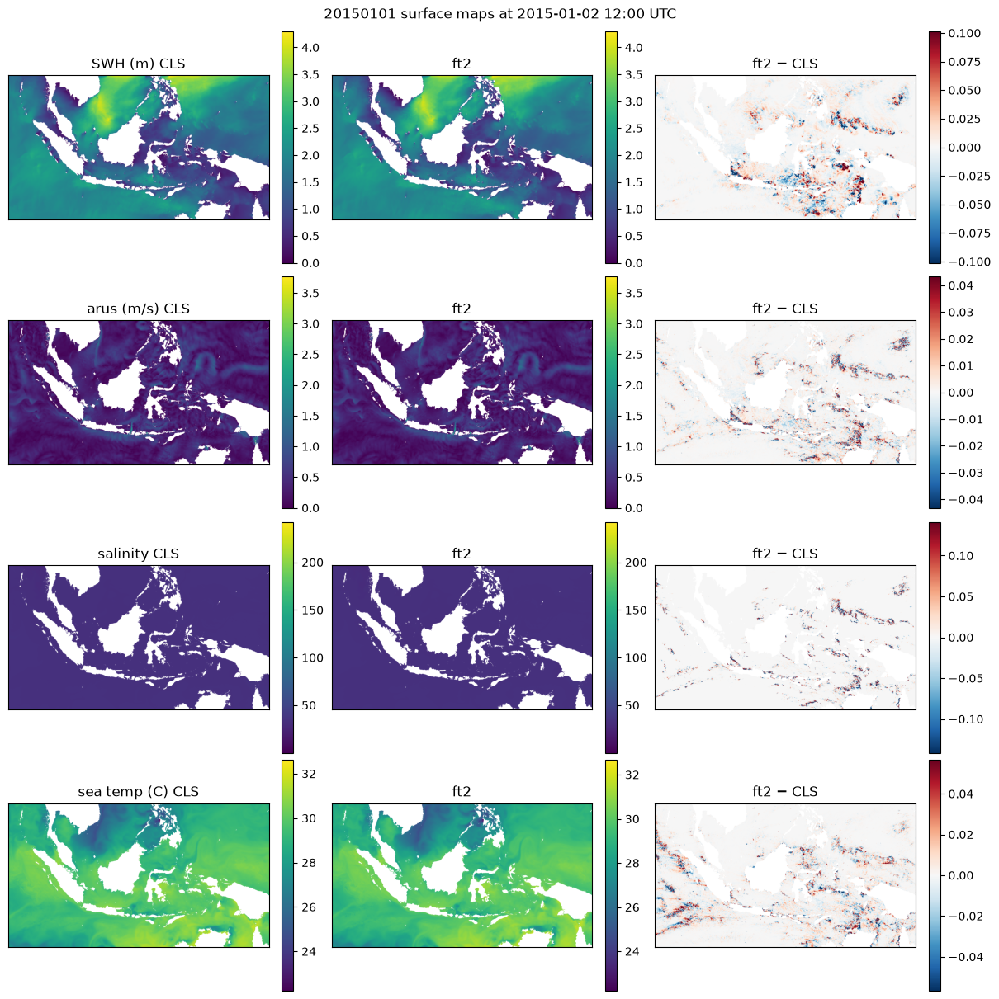

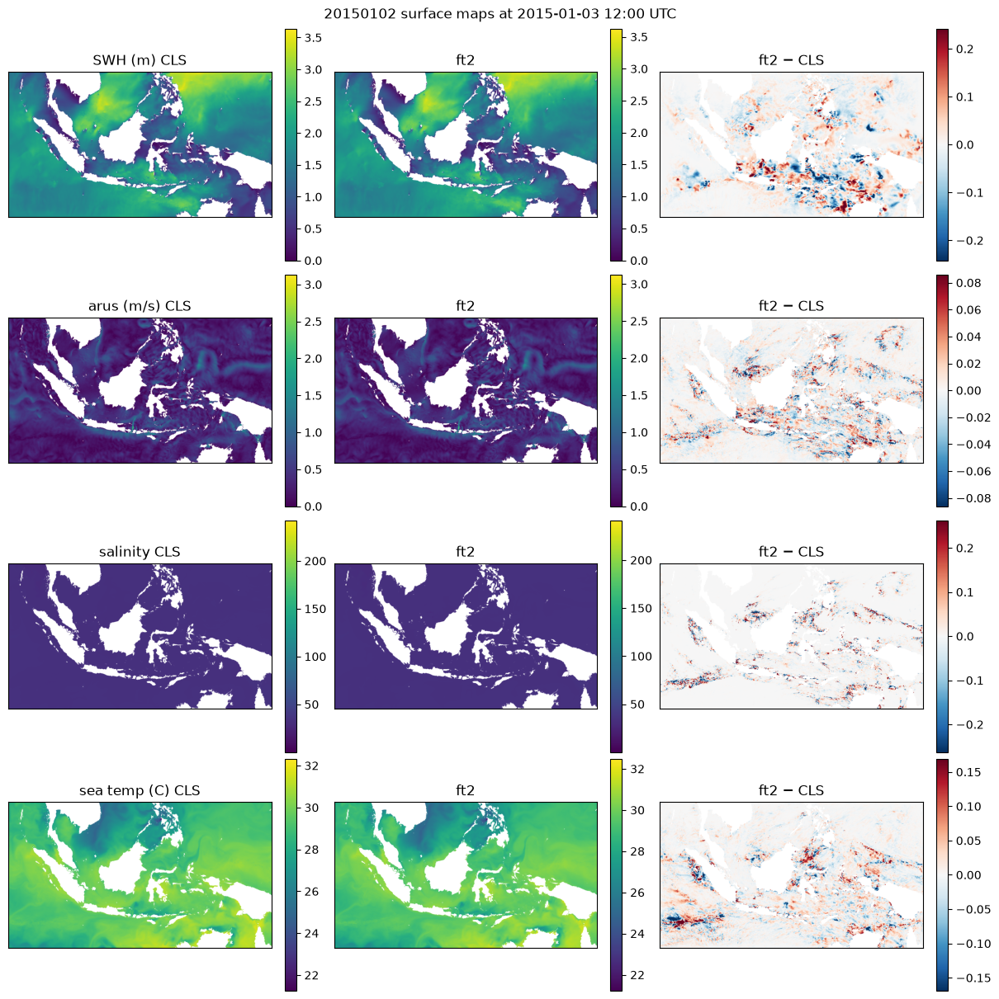

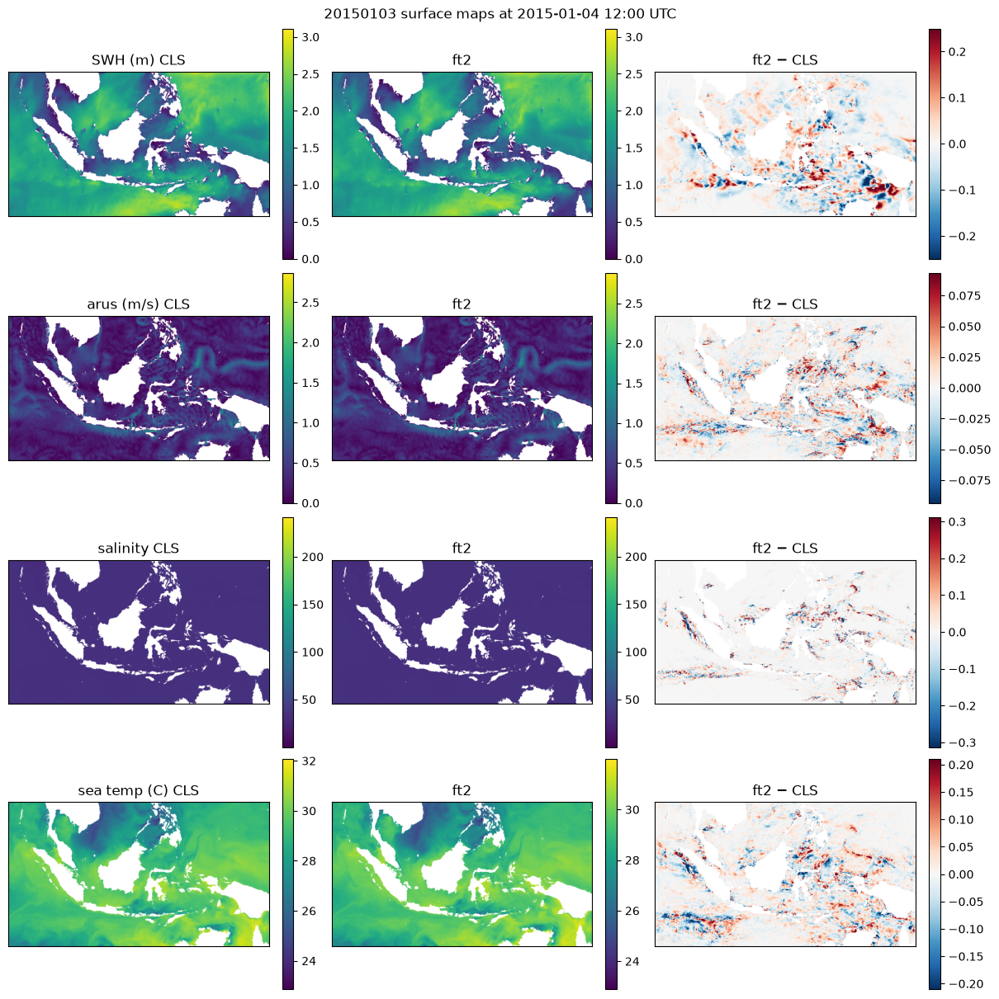

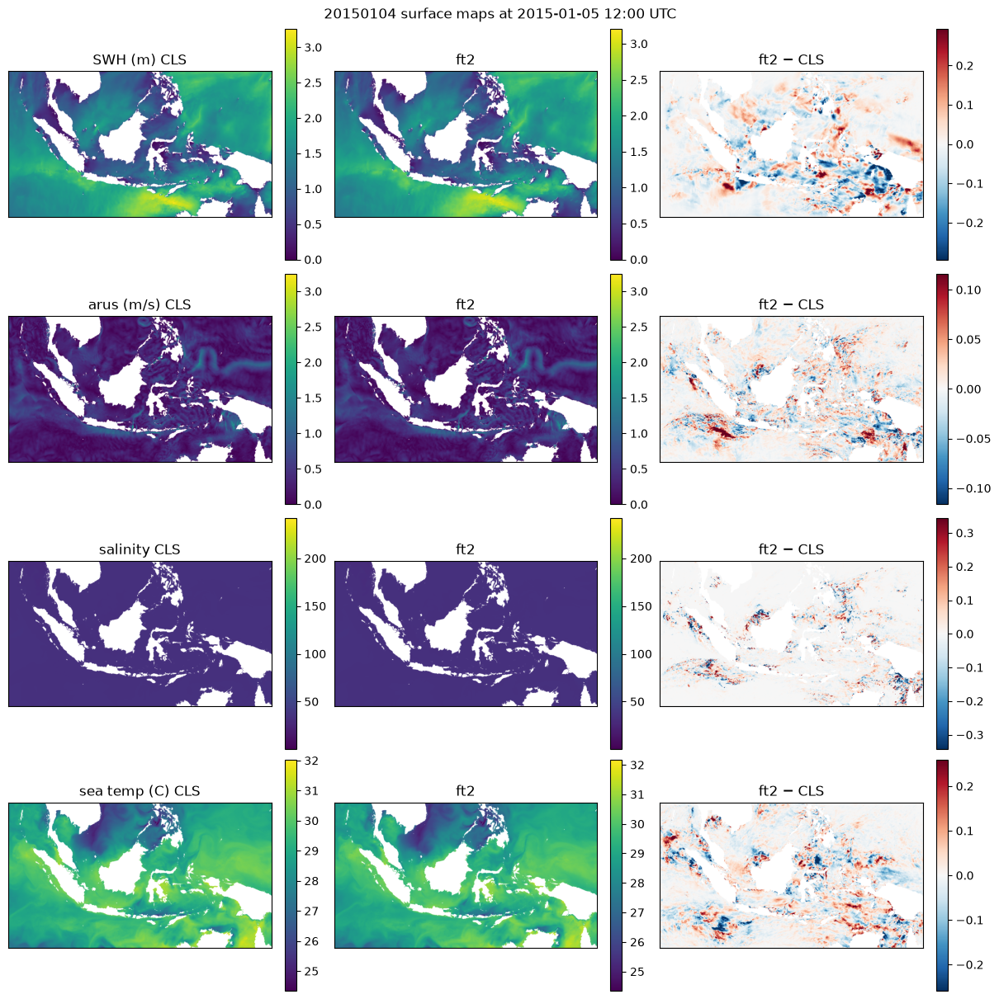

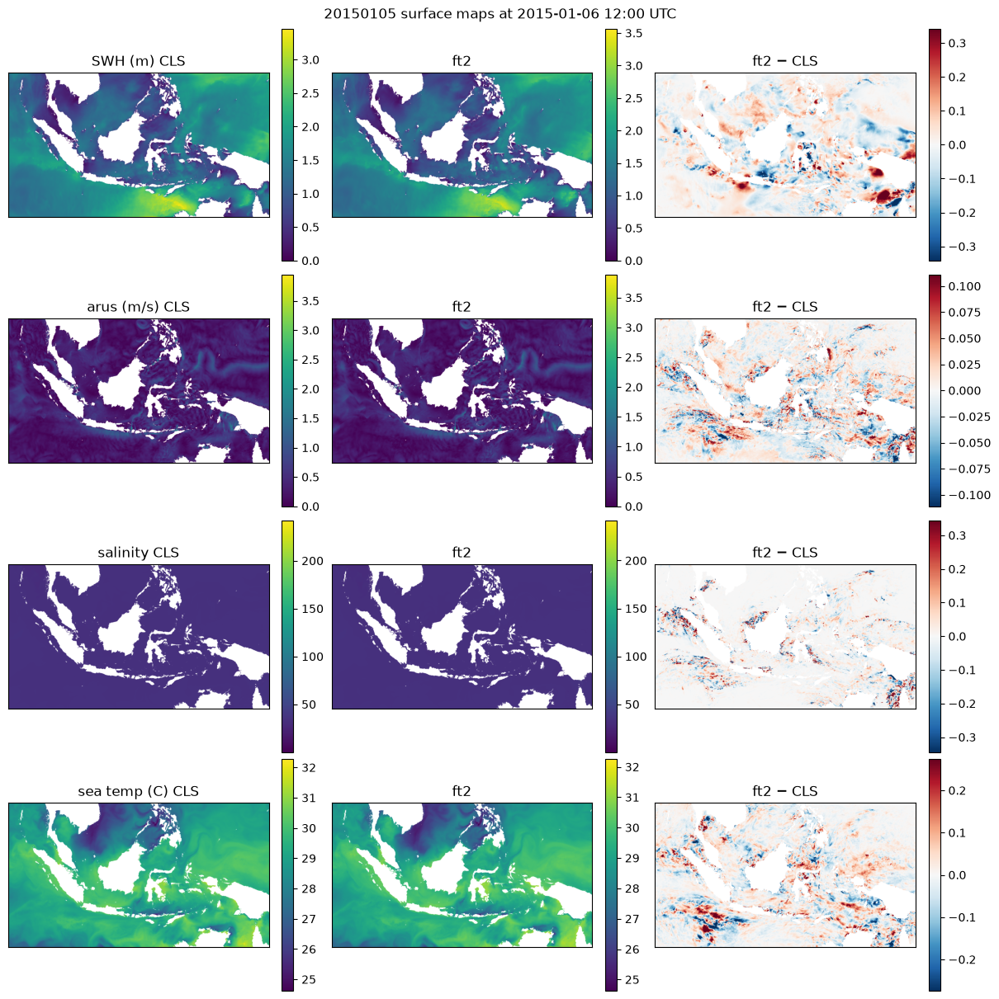

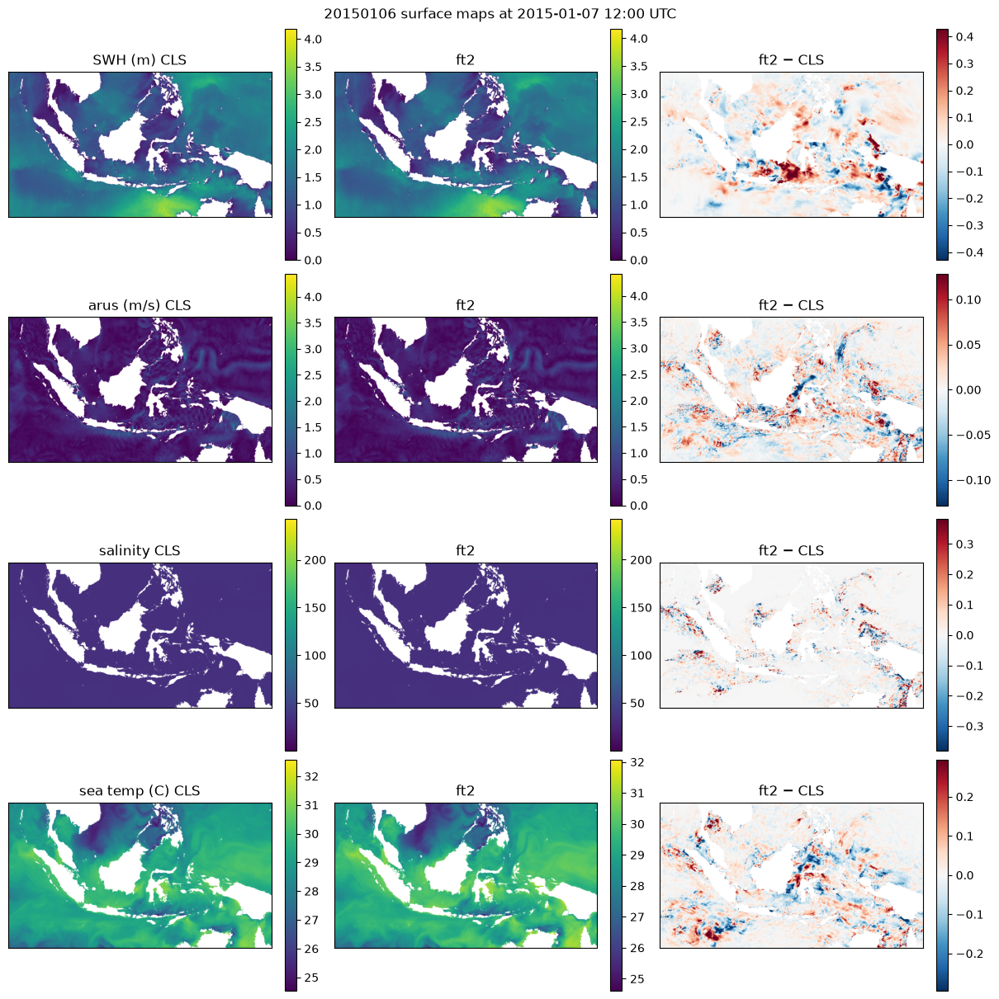

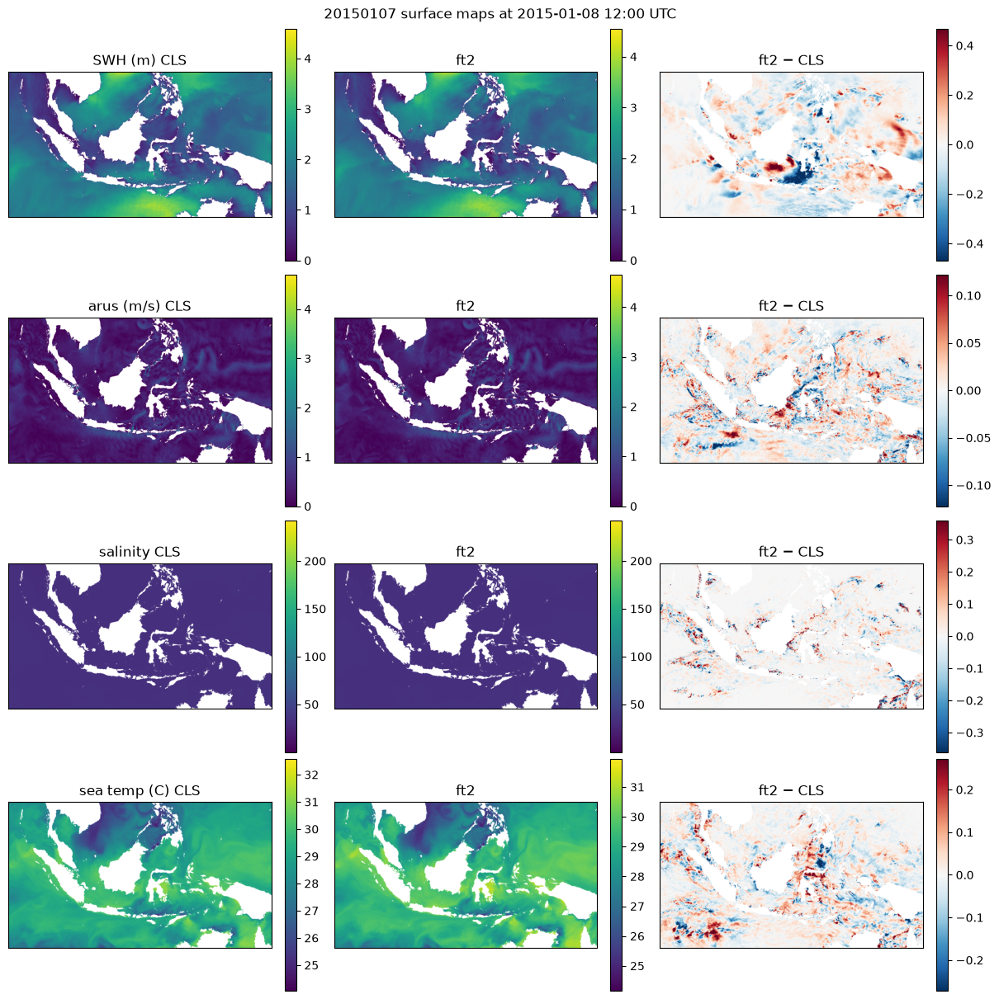

In [2]:
fig, axes = plt.subplots(
    3, len(PLOT_FIELDS), figsize=(3.3 * len(PLOT_FIELDS), 7.6), sharex="col", constrained_layout=True
)
for column, key in enumerate(PLOT_FIELDS):
    sample = series[series.field == key].sort_values("time")
    axes[0, column].plot(sample.time, sample.cls_mean, color="#005f73", label="CLS")
    axes[0, column].plot(sample.time, sample.ft2_mean, color="#9b2226", label="ft2")
    axes[0, column].set_title(LABELS[key])
    axes[1, column].plot(sample.time, sample.bias, color="#9b2226", label="bias")
    axes[1, column].plot(sample.time, sample.rmse, color="#005f73", label="RMSE")
    axes[1, column].axhline(0, color="0.55", lw=0.6)
    axes[2, column].plot(sample.time, sample["corr"], color="#005f73")
    axes[2, column].set_ylim(-0.05, 1.05)
    for row in range(3):
        axes[row, column].xaxis.set_major_formatter(mdates.DateFormatter("%d"))
        axes[row, column].grid(True, axis="y", alpha=0.25)
axes[0, 0].set_ylabel("domain mean")
axes[1, 0].set_ylabel("ft2 − CLS")
axes[2, 0].set_ylabel("correlation")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.suptitle("Domain mean and gap, 1–7 January surface")
plt.show()

for tag, (stamp, cls_fields, ft2_fields) in end_maps.items():
    fig, axes = plt.subplots(len(PLOT_FIELDS), 3, figsize=(12, 3.0 * len(PLOT_FIELDS)), constrained_layout=True)
    for row, key in enumerate(PLOT_FIELDS):
        cls_field = cls_fields[key]
        ft2_field = ft2_fields[key]
        delta = ft2_field - cls_field
        finite = delta[np.isfinite(delta)]
        span = float(np.quantile(np.abs(finite), 0.99)) if finite.size else 1.0
        span = max(span, 1e-12)
        panels = (
            (cls_field, "CLS", "viridis", {}),
            (ft2_field, "ft2", "viridis", {}),
            (delta, "ft2 − CLS", "RdBu_r", {"vmin": -span, "vmax": span}),
        )
        for column, (field, title, cmap, limits) in enumerate(panels):
            image = axes[row, column].imshow(field, origin="lower", cmap=cmap, **limits)
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
            axes[row, column].set_title(f"{LABELS[key]} {title}" if column == 0 else title)
            fig.colorbar(image, ax=axes[row, column], fraction=0.046)
    fig.suptitle(f"{tag} surface maps at {stamp.strftime('%Y-%m-%d %H:%M')} UTC")
    plt.show()
